# Q2 - Copy Mutate Algorithm with Addition and Deletion
Group No: ____

In Q1 we only did **modification** (replace one ingredient with another). Here we also add **addition** and **deletion** of ingredients, so the recipe size can now change.



In [1]:
import os
import random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 1: Parameters
- `P_MOD`, `P_ADD`, `P_DEL` = chance of modification, addition, deletion (they should add up to 1)
- `MIN_SIZE`, `MAX_SIZE` = a recipe cannot become smaller or bigger than this. We take MAX_SIZE as the biggest recipe in the real data. Without a limit the recipes could become empty or very big.

Other parameters are same as Q1. Plots are saved in the `Q2_output` folder.

In [2]:
DATA_PATH = "ner_ingredient_pairs.csv"
OUTPUT_DIR = "Q2_output"
N_EPOCHS = 10
NR0 = 300
KB_RATIO = 0.02
N_RUNS = 5
SEED = 42

P_MOD = 1 / 3
P_ADD = 1 / 3
P_DEL = 1 / 3
MIN_SIZE = 2

## Step 2: Load the data
Same as Q1. We get the number of recipes, nature basket and the starting recipe size `s` (average recipe size). Also `MAX_SIZE` = size of the biggest real recipe.

In [3]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(DATA_PATH):
    DATA_PATH = "/mnt/user-data/uploads/ner_ingredient_pairs.csv"

df = pd.read_csv(DATA_PATH)
df["ingredient"] = df["extracted_ingredient_name"].astype(str).str.strip().str.lower()

real_recipes = df.groupby("recipe_id")["ingredient"].apply(set)
real_sizes = real_recipes.apply(len)

N_RECIPES = len(real_recipes)
NATURE_BASKET = sorted(df["ingredient"].unique())
NB_SIZE = len(NATURE_BASKET)
s = int(round(real_sizes.mean()))
MAX_SIZE = int(real_sizes.max())

print("Number of recipes:", N_RECIPES)
print("Size of nature basket:", NB_SIZE)
print("Starting recipe size s:", s)
print("MIN_SIZE and MAX_SIZE:", MIN_SIZE, MAX_SIZE)

Number of recipes: 7538
Size of nature basket: 5893
Starting recipe size s: 13
MIN_SIZE and MAX_SIZE: 2 45


## Step 3: Epochs, recipes per epoch and kitchen basket size
Same as Q1.

In [4]:
RECIPES_PER_EPOCH = round(N_RECIPES / N_EPOCHS)

epoch_targets = []
for k in range(1, N_EPOCHS + 1):
    epoch_targets.append(min(k * RECIPES_PER_EPOCH, N_RECIPES))

KB_SIZE = max(round(KB_RATIO * NB_SIZE), s + 1)

print("Recipes per epoch:", RECIPES_PER_EPOCH)
print("Target recipes at end of each epoch:", epoch_targets)
print("Kitchen basket size:", KB_SIZE)

Recipes per epoch: 754
Target recipes at end of each epoch: [754, 1508, 2262, 3016, 3770, 4524, 5278, 6032, 6786, 7538]
Kitchen basket size: 118


## Step 4: Primordial cuisine (epoch 0)
Same as Q1: random kitchen basket from nature basket, and `NR0` unique random recipes of size `s`.

In [5]:
def make_primordial(rng):
    kb = rng.sample(NATURE_BASKET, KB_SIZE)
    recipes = []
    seen = set()
    while len(recipes) < NR0:
        r = rng.sample(kb, s)
        key = frozenset(r)
        if key not in seen:
            seen.add(key)
            recipes.append(r)
    return kb, recipes, seen

## Step 5: Modification, addition and deletion

In [6]:
def modify(child, kb, rng):
    while True:
        pos = rng.randrange(len(child))
        new_ing = rng.choice(kb)
        if new_ing != child[pos] and new_ing not in child:
            child[pos] = new_ing
            return child


def add(child, kb, rng):
    while True:
        new_ing = rng.choice(kb)
        if new_ing not in child:
            child.append(new_ing)
            return child


def delete(child, rng):
    pos = rng.randrange(len(child))
    child.pop(pos)
    return child


def mutate(parent, kb, rng):
    child = list(parent)          # copy of the recipe
    while True:
        x = rng.random()
        if x < P_MOD:
            return modify(child, kb, rng)
        elif x < P_MOD + P_ADD:
            if len(child) < MAX_SIZE:
                return add(child, kb, rng)
        else:
            if len(child) > MIN_SIZE:
                return delete(child, rng)

In [7]:
def get_stats(recipes, counts):
    # recipe size distribution and normalised frequency (sorted high to low)
    n = len(recipes)
    size_count = Counter(len(r) for r in recipes)
    freq = sorted(counts.values(), reverse=True)
    freq = np.array(freq) / n
    return {"n": n, "size_count": size_count, "freq": freq}


def run_cuisine(seed):
    rng = random.Random(seed)
    kb, recipes, seen = make_primordial(rng)
    counts = Counter()                      # in how many recipes each ingredient is present
    for r in recipes:
        counts.update(r)

    all_epochs = []
    for target in epoch_targets:
        while len(recipes) < target:
            parent = rng.choice(recipes)
            child = mutate(parent, kb, rng)
            key = frozenset(child)
            if key in seen:                 # recipe already there, skip it
                continue
            seen.add(key)
            recipes.append(child)
            counts.update(child)
        all_epochs.append(get_stats(recipes, counts))   # save stats at end of epoch
    return all_epochs

## Step 6: One run - plots for each epoch
Recipe size distribution and normalised frequency-rank distribution for every epoch (one run).

In [8]:
run0 = run_cuisine(SEED)
print("recipes in final cuisine:", run0[-1]["n"])
print("ingredients used in final cuisine:", len(run0[-1]["freq"]))

sizes_final = []
for size, c in run0[-1]["size_count"].items():
    sizes_final += [size] * c
print("final recipe size: min", min(sizes_final), "max", max(sizes_final), "mean", round(np.mean(sizes_final), 2))

recipes in final cuisine: 7538
ingredients used in final cuisine: 118
final recipe size: min 7 max 19 mean 12.95


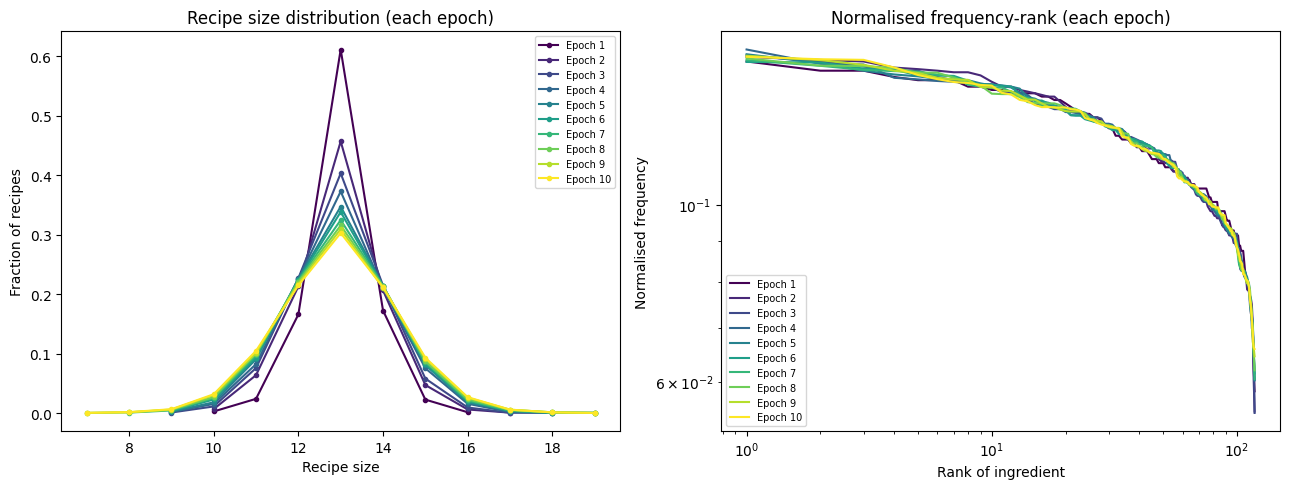

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
colors = plt.cm.viridis(np.linspace(0, 1, N_EPOCHS))

for i in range(N_EPOCHS):
    st = run0[i]
    sz = sorted(st["size_count"])
    frac = [st["size_count"][x] / st["n"] for x in sz]
    ax1.plot(sz, frac, "o-", color=colors[i], markersize=3, label="Epoch " + str(i + 1))

    ranks = np.arange(1, len(st["freq"]) + 1)
    ax2.loglog(ranks, st["freq"], color=colors[i], label="Epoch " + str(i + 1))

ax1.set_xlabel("Recipe size")
ax1.set_ylabel("Fraction of recipes")
ax1.set_title("Recipe size distribution (each epoch)")
ax1.legend(fontsize=7)

ax2.set_xlabel("Rank of ingredient")
ax2.set_ylabel("Normalised frequency")
ax2.set_title("Normalised frequency-rank (each epoch)")
ax2.legend(fontsize=7)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Q2_Fig1_RecipeSize_FreqRank_per_Epoch.png"), dpi=200)
plt.show()

## Step 7: Run 5 instances
Run the whole evolution 5 times with different seeds and use the final epoch of every run.

In [10]:
runs = []
for r in range(N_RUNS):
    runs.append(run_cuisine(SEED + r))
    print("run", r + 1, "done")

final = [run[-1] for run in runs]

run 1 done
run 2 done
run 3 done
run 4 done
run 5 done


## Step 8: Recipe size distribution (mean and std)
Fraction of recipes of each size in every run, then mean and std over the 5 runs. Grey bars are the real data.

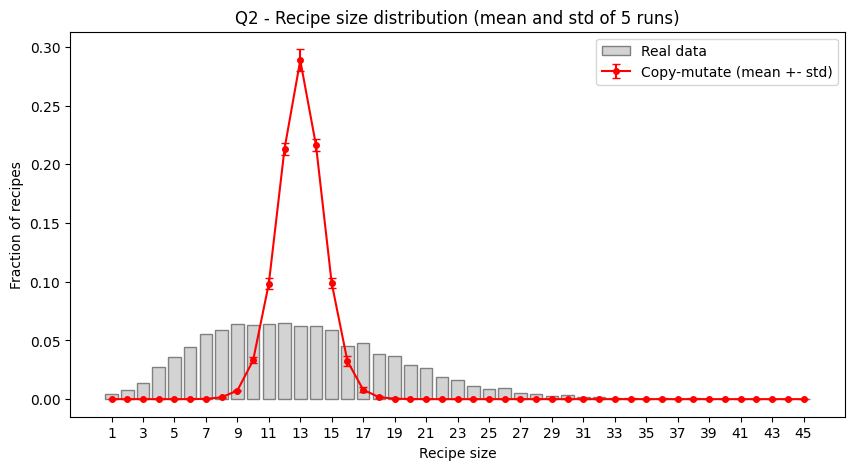

In [11]:
sizes = np.arange(1, MAX_SIZE + 1)

all_frac = []
for f in final:
    row = [f["size_count"].get(x, 0) / f["n"] for x in sizes]
    all_frac.append(row)
all_frac = np.array(all_frac)

mean_size = all_frac.mean(axis=0)
std_size = all_frac.std(axis=0)

real_frac = [(real_sizes == x).mean() for x in sizes]

plt.figure(figsize=(10, 5))
plt.bar(sizes, real_frac, color="lightgrey", edgecolor="grey", label="Real data")
plt.errorbar(sizes, mean_size, yerr=std_size, fmt="o-", color="red", markersize=4, capsize=3, label="Copy-mutate (mean +- std)")
plt.xticks(sizes[::2])
plt.xlabel("Recipe size")
plt.ylabel("Fraction of recipes")
plt.title("Q2 - Recipe size distribution (mean and std of 5 runs)")
plt.legend()
plt.savefig(os.path.join(OUTPUT_DIR, "Q2_Fig2_RecipeSizeDistribution_MeanSD.png"), dpi=200)
plt.show()

## Step 9: Normalised frequency-rank distribution
Normalised frequency = (number of recipes having the ingredient) / (total recipes). Sorted high to low and plotted against rank on log-log scale. Left: full view with the real data (grey). Right: zoom on the simulated part so that the std can be seen.

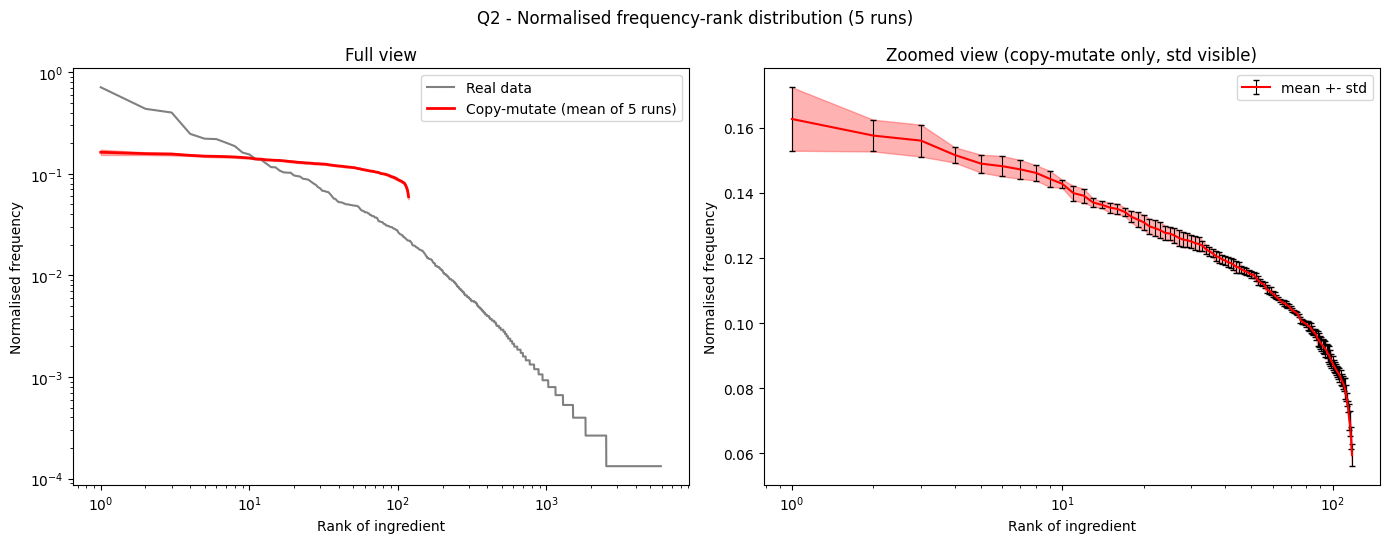

In [12]:
L = min(len(f["freq"]) for f in final)          # same number of ranks for all runs
F = np.array([f["freq"][:L] for f in final])
mean_f = F.mean(axis=0)
std_f = F.std(axis=0)
ranks = np.arange(1, L + 1)

# real data
real_counts = df.drop_duplicates(["recipe_id", "ingredient"])["ingredient"].value_counts()
real_freq = real_counts.values / N_RECIPES

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

ax1.loglog(np.arange(1, len(real_freq) + 1), real_freq, color="grey", label="Real data")
ax1.loglog(ranks, mean_f, color="red", linewidth=2, label="Copy-mutate (mean of 5 runs)")
ax1.fill_between(ranks, np.clip(mean_f - std_f, 1e-6, None), mean_f + std_f, color="red", alpha=0.3)
ax1.set_xlabel("Rank of ingredient")
ax1.set_ylabel("Normalised frequency")
ax1.set_title("Full view")
ax1.legend()

ax2.errorbar(ranks, mean_f, yerr=std_f, fmt="-", color="red", ecolor="black", elinewidth=0.8, capsize=2, label="mean +- std")
ax2.fill_between(ranks, mean_f - std_f, mean_f + std_f, color="red", alpha=0.3)
ax2.set_xscale("log")
ax2.set_xlabel("Rank of ingredient")
ax2.set_ylabel("Normalised frequency")
ax2.set_title("Zoomed view (copy-mutate only, std visible)")
ax2.legend()

plt.suptitle("Q2 - Normalised frequency-rank distribution (5 runs)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Q2_Fig3_NormalisedFreqRank.png"), dpi=200)
plt.show()

## Conclusion
- Now the recipe size is not fixed. Because of addition and deletion, the recipe sizes spread out around the starting size `s` and make a bell shaped curve (mostly sizes 9 to 17). The std across the 5 runs is small, so the runs give almost the same curve.
- The simulated curve is much narrower than the real data (real recipes go from 1 to 45 ingredients), because adding and deleting only change the size by 1 at a time and copied recipes stay close to their parent.
- The frequency-rank curve is still flat compared to the real data and stops early, because all the kitchen basket ingredients still have the same chance of being picked. We will try to fix this in Q3 by giving fitness to ingredients.

Saved plots (in the `Q2_output` folder): `Q2_Fig1_RecipeSize_FreqRank_per_Epoch.png`, `Q2_Fig2_RecipeSizeDistribution_MeanSD.png`, `Q2_Fig3_NormalisedFreqRank.png`